# Scene diversity: 25 random scenes with post-processing

A stratified sample of the scene vocabulary: 25 random scene types and seeds,
each with a random sensor/atmosphere treatment. The degradation chain is
applied in physical order by `apply_sensor` (atmosphere → optics → noise), and
every frame gets the same mild sensor noise. Cloud cover is applied to only
about 28 % of the frames (at least 70 % stay clear), with varying coverage.

This notebook is part of the visual-inspection rounds: it is meant to reveal
which combinations read well and where diversity is still lacking.

In [1]:
%matplotlib inline

import io

import matplotlib.pyplot as plt
import numpy as np


def check_figure_size(fig, max_mb=5.0):
    """Check that a figure's PNG stays below ``max_mb`` megabytes."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi)
    size_mb = buffer.getbuffer().nbytes / 1e6
    print(f"figure: {size_mb:.2f} MB")
    assert size_mb <= max_mb, f"figure too big: {size_mb:.2f} MB > {max_mb} MB"

## 25 random scenes

Scene type and seed are sampled independently; each frame also gets a random
sensor treatment. `apply_sensor` runs the chain in physical order: haze and
cloud occlusion first, then blur, then a mild, bounded Gaussian/Poisson noise
on every frame. Cloud cover is applied to 7 of the 25 frames (28 %), with
coverage in [0.2, 0.5].

figure: 1.47 MB


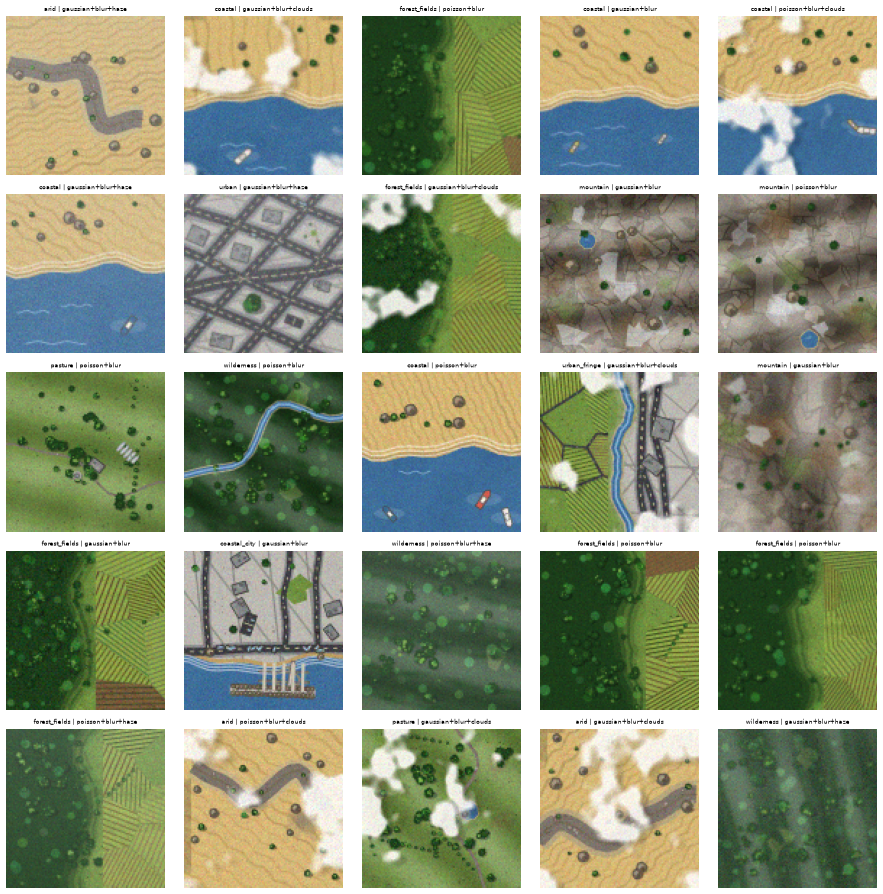

In [2]:
from mlpsyn.scene import SCENES, generate_scene
from mlpsyn.sensor import apply_sensor


def generate_scene_grid(seed=2024):
    rng = np.random.default_rng(seed)
    names = sorted(SCENES)
    n = 25
    cloudy = set(rng.choice(n, size=7, replace=False).tolist())  # 28 % cloudy, 72 % clear

    fig, axes = plt.subplots(5, 5, figsize=(15, 15), dpi=60)
    for idx, ax in enumerate(axes.ravel()):
        name = names[int(rng.integers(len(names)))]
        seed = int(rng.integers(0, 10_000))
        image = generate_scene(name, size=110, seed=seed).image

        # Every frame gets the same mild sensor noise; only blur and the
        # atmosphere vary. `apply_sensor` applies haze/clouds *before* noise.
        kind = ["gaussian", "poisson"][int(rng.integers(2))]
        radius = float(rng.uniform(0.0, 0.7))
        haze_strength = float(rng.uniform(0.1, 0.25)) if rng.random() < 0.3 else 0.0
        cloud_coverage = float(rng.uniform(0.2, 0.5)) if idx in cloudy else 0.0
        image = apply_sensor(
            image,
            rng,
            kind=kind,
            blur_radius=radius,
            haze_strength=haze_strength,
            cloud_coverage=cloud_coverage,
        )
        label = kind
        if radius > 0:
            label += "+blur"
        if haze_strength > 0:
            label += "+haze"
        if cloud_coverage > 0:
            label += "+clouds"

        ax.imshow(image)
        ax.set_title(f"{name} | {label}", fontsize=7)
        ax.axis("off")
    plt.tight_layout()
    check_figure_size(fig)
    plt.show()

generate_scene_grid(2024)

### Visual analysis — 25 random scenes

Seven of the 25 frames are cloudy (28 %), so 18 (72 %) are clear.

**Description / good**

- The mix spans the eleven scene types (including the new `coastal_city` with
  breakwaters, piers and marinas) with no type dominating.
- Sensor treatments are recognisable: Gaussian (fine grain), Poisson (speckle),
  blur (soft edges), haze (wash), clouds (large soft masses with shadows).
- Cloudy frames look plausible; cloud coverage varies per frame.
- Scene-level diversity is high: composition, terrain and post-processing vary.
- Cars are now drawn at a realistic ~4-5 px (96 px frames), which also lifted
  their detection AP from 0.12 to 0.18.

**Defects**

- Gaussian noise is subtle at this panel size (low).
- Some scene types repeat by chance; a stratified sampler would guarantee
  coverage (low).
- The hard region boundaries in `forest_fields` / `urban_fringe` (medium) were
  softened and the `forest_fields` mosaic now reaches the frame edge.


figure: 1.53 MB


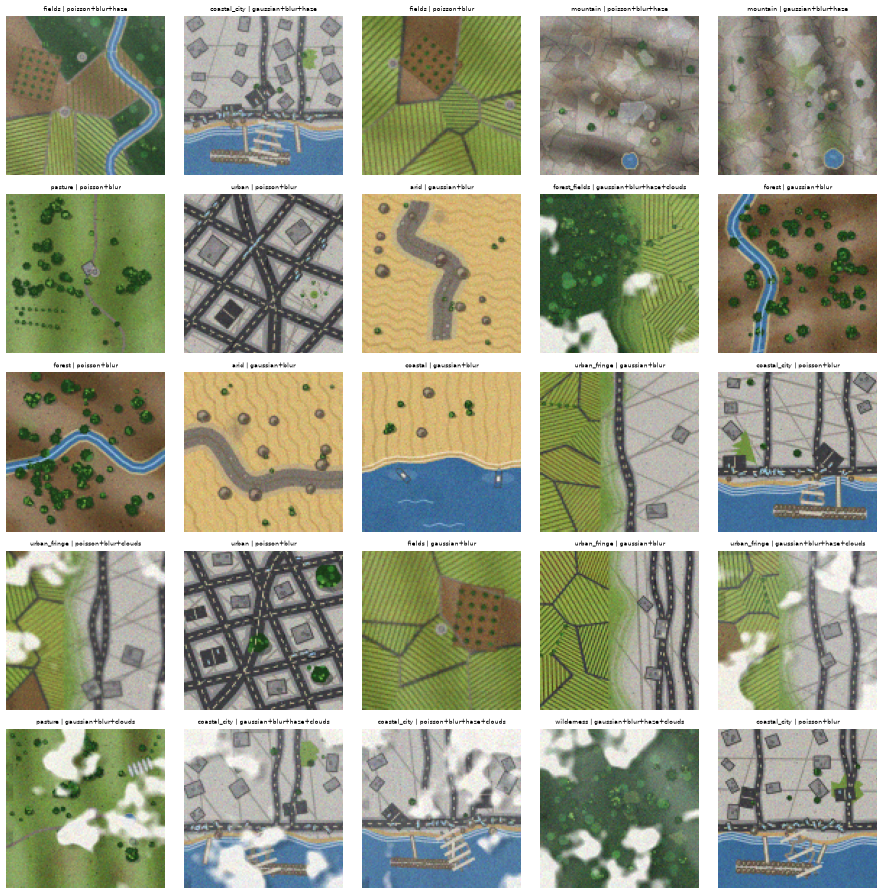

In [3]:
generate_scene_grid(2025)

## Automatic diversity metrics

Human inspection is complemented by `mlpsyn.metrics`: a label histogram,
objects-per-scene range and how evenly object centres cover the frame.

In [4]:
from mlpsyn.metrics import diversity_report
from mlpsyn.scene import SCENES

rng = np.random.default_rng(7)
sample = [
    generate_scene(sorted(SCENES)[int(rng.integers(len(SCENES)))], size=80, seed=int(rng.integers(10_000)))
    for _ in range(30)
]
report = diversity_report(sample, grid=4)
print("scenes:", report["n_scenes"], "objects:", report["objects_total"])
print("objects/scene:", report["objects_min"], "-", report["objects_max"])
print("label entropy:", round(report["label_entropy"], 2))
print("mean spatial coverage:", round(report["mean_spatial_coverage"], 2))
print("labels:", report["labels"])

scenes: 30 objects: 913
objects/scene: 7 - 60
label entropy: 1.88
mean spatial coverage: 0.72
labels: {'boat': 5, 'building': 30, 'bush': 156, 'car': 27, 'conifer': 239, 'field': 88, 'hedgerow': 25, 'orchard': 3, 'parking': 4, 'plaza': 2, 'pond': 3, 'pool': 2, 'rock': 35, 'silo': 5, 'tree': 279, 'truck': 10}


## Semantic segmentation and cloud-occlusion masks

For five varied scenes, each column shows: the **original** image, the same
image with the **object-detection boxes**, a **semantic segmentation** colour
map (pixel classes from `mlpsyn.segmentation`) and the **cloud-occlusion**
mask used by the atmosphere. The RGB image and the labels come from the same
deterministic spec, so they are pixel-aligned.


figure: 0.54 MB


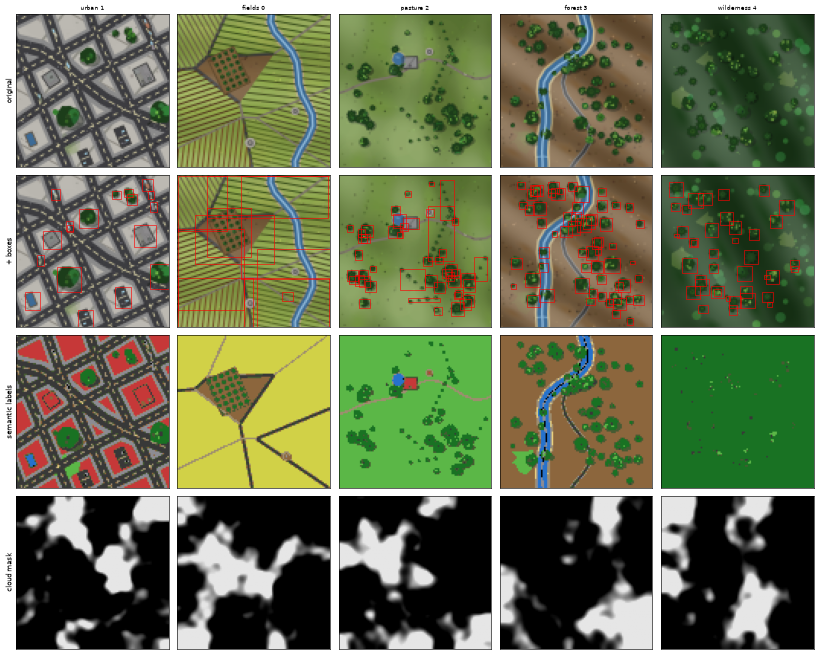

In [5]:
from matplotlib import patches

from mlpsyn.segmentation import CLASS_COLORS, SEGMENTATION_CLASSES, semantic_mask
from mlpsyn.sensor import clouds

palette = np.array(
    [[0, 0, 0]]
    + [[int(255 * c) for c in CLASS_COLORS[name]] for name in SEGMENTATION_CLASSES[1:]],
    dtype=np.uint8,
)

demo = [("urban", 1), ("fields", 0), ("pasture", 2), ("forest", 3), ("wilderness", 4)]
size = 100
fig, axes = plt.subplots(4, len(demo), figsize=(15, 12), dpi=55)
for col, (name, seed) in enumerate(demo):
    rgb = generate_scene(name, size=size, seed=seed).image
    scene, labels = semantic_mask(name, size=size, seed=seed)
    colored = palette[labels]
    rng = np.random.default_rng(seed)
    _, cloud = clouds(rgb, rng, coverage=0.5, return_mask=True)
    axes[0, col].imshow(rgb)
    axes[0, col].set_title(f"{name} {seed}", fontsize=8)
    axes[1, col].imshow(rgb)
    for obj in scene.objects:
        x0, y0, x1, y1 = obj.pixel_bbox(size)
        axes[1, col].add_patch(
            patches.Rectangle(
                (x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=0.8
            )
        )
    axes[2, col].imshow(colored)
    axes[3, col].imshow(cloud, cmap="gray", vmin=0.0, vmax=1.0)
for row, label in enumerate(["original", "+ boxes", "semantic labels", "cloud mask"]):
    axes[row, 0].set_ylabel(label, fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
check_figure_size(fig)
plt.show()


In [6]:
print({i: name for i, name in enumerate(SEGMENTATION_CLASSES)})


{0: 'unlabeled', 1: 'grassland', 2: 'cropland', 3: 'bare_soil', 4: 'vegetation', 5: 'water', 6: 'built', 7: 'road', 8: 'rock', 9: 'sand', 10: 'snow', 11: 'gravel', 12: 'wetland'}
